In [1]:
import os

# Defining the base paths as per Kaggle's mount point
anime_base = "/kaggle/input/datasets/soumikrakshit/anime-faces"
pokemon_base = "/kaggle/input/datasets/jackemartin/pokemon-sprites"

def get_final_paths(root_path, name):
    # Walking the directory to find the actual folder containing image files
    for root, dirs, files in os.walk(root_path):
        image_files = [f for f in files if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        if len(image_files) > 0:
            print(name + " images found at:", root)
            print("Total images:", len(image_files))
            print("Sample files:", image_files[:2])
            return root
    print("No images found for", name, ". Please check the dataset.")
    return None

print("Checking dataset paths")

real_anime_path = get_final_paths(anime_base, "Anime Faces")
real_pokemon_path = get_final_paths(pokemon_base, "Pokemon Sprites")

if real_anime_path and real_pokemon_path:
    print("All paths are correct")

Checking dataset paths
Anime Faces images found at: /kaggle/input/datasets/soumikrakshit/anime-faces/data
Total images: 21551
Sample files: ['21130.png', '9273.png']
Pokemon Sprites images found at: /kaggle/input/datasets/jackemartin/pokemon-sprites/pokemon_images/pokemondb.net
Total images: 33887
Sample files: ['nidorina24.jpg', 'trapinch43.jpg']
All paths are correct


In [2]:
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import os

# Defining the standard GAN preprocessing
gan_transform = transforms.Compose([
    transforms.Resize(64),
    transforms.CenterCrop(64),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Function to safely create a dataloader given a real image path
def create_loader(real_path, batch_size=64):
    parent_dir = os.path.dirname(real_path)
    dataset = datasets.ImageFolder(root=parent_dir, transform=gan_transform)
    
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2,
        pin_memory=True
    )
    return loader

print("Creating data loaders")

# Creating the Anime Loader
anime_loader = create_loader(real_anime_path)
print("Anime loader created with", len(anime_loader), "batches")

# Creating the Pokemon Loader
pokemon_loader = create_loader(real_pokemon_path)
print("Pokemon loader created with", len(pokemon_loader), "batches")

# Verifying a sample batch shape
sample_batch, _ = next(iter(anime_loader))
print("Sample batch shape:", sample_batch.shape)

Creating data loaders
Anime loader created with 674 batches
Pokemon loader created with 530 batches
Sample batch shape: torch.Size([64, 3, 64, 64])


In [3]:
import torch
import torch.nn as nn

# Generator Architecture
class Generator(nn.Module):
    def __init__(self, z_dim=100, channels_img=3, features_g=64):
        super(Generator, self).__init__()
        
        self.gen = nn.Sequential(
            nn.ConvTranspose2d(z_dim, features_g * 16, 4, 1, 0, bias=False),
            nn.BatchNorm2d(features_g * 16),
            nn.ReLU(True),
            
            nn.ConvTranspose2d(features_g * 16, features_g * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features_g * 8),
            nn.ReLU(True),
            
            nn.ConvTranspose2d(features_g * 8, features_g * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features_g * 4),
            nn.ReLU(True),
            
            nn.ConvTranspose2d(features_g * 4, features_g * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features_g * 2),
            nn.ReLU(True),
            
            nn.ConvTranspose2d(features_g * 2, channels_img, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, x):
        return self.gen(x)

# Discriminator / Critic
class Discriminator(nn.Module):
    def __init__(self, channels_img=3, features_d=64, use_sigmoid=True):
        super(Discriminator, self).__init__()
        self.use_sigmoid = use_sigmoid
        
        self.disc = nn.Sequential(
            nn.Conv2d(channels_img, features_d, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Conv2d(features_d, features_d * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features_d * 2),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Conv2d(features_d * 2, features_d * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features_d * 4),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Conv2d(features_d * 4, features_d * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features_d * 8),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Conv2d(features_d * 8, 1, 4, 1, 0, bias=False),
        )

    def forward(self, x):
        output = self.disc(x)
        if self.use_sigmoid:
            return torch.sigmoid(output)
        return output

# Weight initialization
def weights_init(m):
    classname = m.__class__.__name__
    if 'Conv' in classname:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif 'BatchNorm' in classname:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

print("Models are defined")

Models are defined


In [4]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Setting up Device:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# 2. Hyperparameters
lr = 0.0002
beta1 = 0.5
beta2 = 0.999
z_dim = 100

# 3. Initializing Models
gen_dcgan = Generator(z_dim=z_dim).to(device)
disc_dcgan = Discriminator(use_sigmoid=True).to(device)

# 4. Applying weight initialization
gen_dcgan.apply(weights_init)
disc_dcgan.apply(weights_init)

# 5. Loss and Optimizers
criterion = nn.BCELoss()

optimizer_g = optim.Adam(gen_dcgan.parameters(), lr=lr, betas=(beta1, beta2))
optimizer_d = optim.Adam(disc_dcgan.parameters(), lr=lr, betas=(beta1, beta2))

# 6. Fixed noise for monitoring
fixed_noise = torch.randn(64, z_dim, 1, 1).to(device)

print("DCGAN setup complete on", device)

DCGAN setup complete on cuda:0


In [5]:
# 1. Update the loss function
criterion = nn.BCEWithLogitsLoss()

# 2. Disable Sigmoid in Discriminator
disc_dcgan.use_sigmoid = False

print("Loss function updated and sigmoid removed from discriminator")

Loss function updated and sigmoid removed from discriminator


In [6]:
import torch
from torch import amp 
import torchvision.utils as vutils

# Setup:
scaler = amp.GradScaler('cuda') 
G_losses, D_losses, img_list = [], [], []

print("Starting DCGAN training")

# Using the anime_loader:
current_loader = anime_loader 

# Total rounds of training:
for epoch in range(30): 
    for i, data in enumerate(current_loader, 0):
        
        # 1. PREPARING DATA:
        real_images = data[0].to(device)
        b_size = real_images.size(0)
        
        # Labels
        label_real = torch.full((b_size,), 1.0, device=device)
        label_fake = torch.full((b_size,), 0.0, device=device)

        # STEP 1: TRAINING DISCRIMINATOR
        optimizer_d.zero_grad()
        
        with amp.autocast('cuda'):
            output_real = disc_dcgan(real_images).view(-1)
            lossD_real = criterion(output_real, label_real)
            
            noise = torch.randn(b_size, 100, 1, 1, device=device)
            fake_images = gen_dcgan(noise)
          
            output_fake = disc_dcgan(fake_images.detach()).view(-1)
            lossD_fake = criterion(output_fake, label_fake)
            
            lossD = lossD_real + lossD_fake
            
        scaler.scale(lossD).backward()
        scaler.step(optimizer_d) 
        scaler.update()

        # STEP 2: TRAINING GENERATOR
        optimizer_g.zero_grad()
        
        with amp.autocast('cuda'):
            output = disc_dcgan(fake_images).view(-1)
            lossG = criterion(output, label_real) 
            
        scaler.scale(lossG).backward()
        scaler.step(optimizer_g) 
        scaler.update()

        # Saving losses
        G_losses.append(lossG.item())
        D_losses.append(lossD.item())

        # Logging
        if i % 100 == 0:
            print("Epoch", epoch, "Batch", i, "/", len(current_loader),
                  "Loss_D:", round(lossD.item(), 4),
                  "Loss_G:", round(lossG.item(), 4))

    # Saving sample images
    with torch.no_grad():
        samples = gen_dcgan(fixed_noise).detach().cpu()
        img_list.append(vutils.make_grid(samples, padding=2, normalize=True))
    
    # Saving weights every 5 epochs
    if (epoch + 1) % 5 == 0:
        file_name = "dcgan_gen_epoch_" + str(epoch + 1) + ".pth"
        torch.save(gen_dcgan.state_dict(), file_name)
        print("Saved weights:", file_name)

print("Training complete. Files are saved in the working folder")

Starting DCGAN training
Epoch 0 Batch 0 / 674 Loss_D: 1.2191 Loss_G: 1.442
Epoch 0 Batch 100 / 674 Loss_D: 1.9954 Loss_G: 6.7665
Epoch 0 Batch 200 / 674 Loss_D: 1.294 Loss_G: 2.8803
Epoch 0 Batch 300 / 674 Loss_D: 1.6134 Loss_G: 2.3888
Epoch 0 Batch 400 / 674 Loss_D: 1.2889 Loss_G: 3.5402
Epoch 0 Batch 500 / 674 Loss_D: 1.1529 Loss_G: 6.2124
Epoch 0 Batch 600 / 674 Loss_D: 0.9341 Loss_G: 2.5689
Epoch 1 Batch 0 / 674 Loss_D: 1.0588 Loss_G: 2.5714
Epoch 1 Batch 100 / 674 Loss_D: 1.0098 Loss_G: 1.6436
Epoch 1 Batch 200 / 674 Loss_D: 1.3249 Loss_G: 4.6467
Epoch 1 Batch 300 / 674 Loss_D: 1.0588 Loss_G: 3.1846
Epoch 1 Batch 400 / 674 Loss_D: 0.7696 Loss_G: 2.8824
Epoch 1 Batch 500 / 674 Loss_D: 0.6717 Loss_G: 5.2712
Epoch 1 Batch 600 / 674 Loss_D: 0.7571 Loss_G: 3.0897
Epoch 2 Batch 0 / 674 Loss_D: 0.8663 Loss_G: 3.6082
Epoch 2 Batch 100 / 674 Loss_D: 0.7002 Loss_G: 4.2152
Epoch 2 Batch 200 / 674 Loss_D: 0.5354 Loss_G: 2.1934
Epoch 2 Batch 300 / 674 Loss_D: 0.7258 Loss_G: 3.1863
Epoch 2 Batc

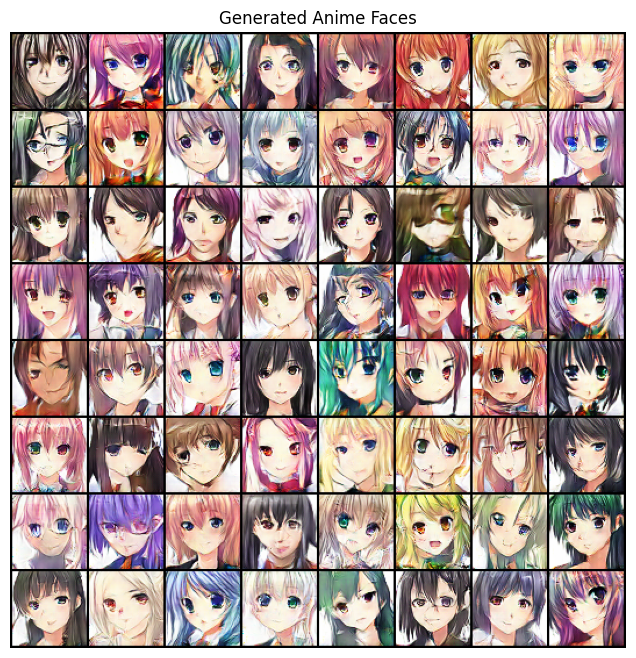

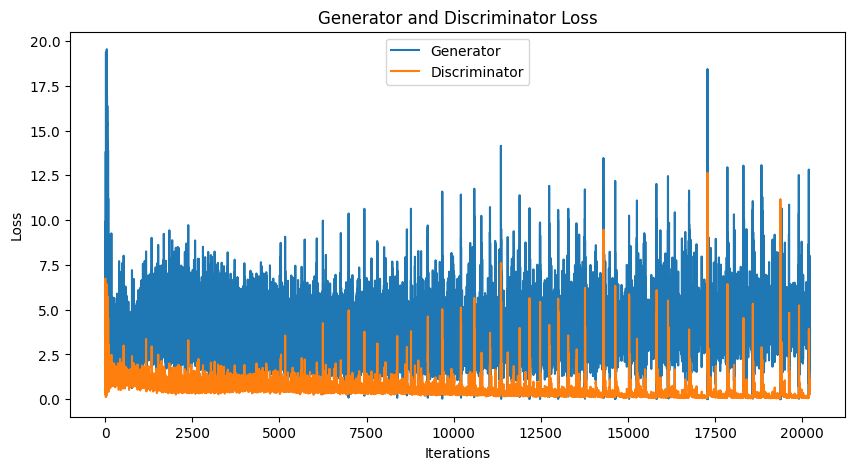

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# 1. Visualizing the Anime Faces:
try:
    if 'img_list' in locals() and len(img_list) > 0:
        plt.figure(figsize=(8,8))
        plt.axis("off")
        plt.title("Generated Anime Faces")
        
        last_grid = img_list[-1].cpu() if torch.is_tensor(img_list[-1]) else img_list[-1]
        plt.imshow(np.transpose(last_grid, (1, 2, 0)))
        plt.show()
    else:
        print("Anime image list is empty")
except Exception as e:
    print("Error showing images:", e)

# 2. Plotting the Loss Curves:
try:
    if 'G_losses' in locals() and len(G_losses) > 0:
        plt.figure(figsize=(10,5))
        plt.title("Generator and Discriminator Loss")
        
        plt.plot(G_losses, label="Generator")
        plt.plot(D_losses, label="Discriminator")
        
        plt.xlabel("Iterations")
        plt.ylabel("Loss")
        plt.legend()
        plt.show()
    else:
        print("Loss data not found or empty")
except Exception as e:
    print("Error plotting losses:", e)

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch import amp 
import torchvision.utils as vutils

# 1. SETUP & RESET
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
current_loader = pokemon_loader
z_dim = 100
lr = 0.0002
beta1 = 0.5
beta2 = 0.999

# Re-initializing models
gen_pokemon = Generator(z_dim=z_dim).to(device)
disc_pokemon = Discriminator(use_sigmoid=False).to(device)
gen_pokemon.apply(weights_init)
disc_pokemon.apply(weights_init)

# Loss and optimizers
criterion = nn.BCEWithLogitsLoss()
optimizer_g = optim.Adam(gen_pokemon.parameters(), lr=lr, betas=(beta1, beta2))
optimizer_d = optim.Adam(disc_pokemon.parameters(), lr=lr, betas=(beta1, beta2))
scaler = amp.GradScaler('cuda') 

# Tracking lists
pokemon_img_list = []
pokemon_G_losses = []
pokemon_D_losses = []

print("Starting Pokemon training")

# 2. TRAINING LOOP
for epoch in range(10): 
    for i, data in enumerate(current_loader, 0):
        
        # PREPARE DATA
        real_images = data[0].to(device)
        b_size = real_images.size(0)
        label_real = torch.full((b_size,), 1.0, device=device)
        label_fake = torch.full((b_size,), 0.0, device=device)

        # STEP 1: TRAIN DISCRIMINATOR
        optimizer_d.zero_grad()
        with amp.autocast('cuda'):
            output_real = disc_pokemon(real_images).view(-1)
            lossD_real = criterion(output_real, label_real)
            
            noise = torch.randn(b_size, z_dim, 1, 1, device=device)
            fake_images = gen_pokemon(noise)
            output_fake = disc_pokemon(fake_images.detach()).view(-1)
            lossD_fake = criterion(output_fake, label_fake)
            
            lossD = lossD_real + lossD_fake
            
        scaler.scale(lossD).backward()
        scaler.step(optimizer_d)
        scaler.update()

        # STEP 2: TRAIN GENERATOR
        optimizer_g.zero_grad()
        with amp.autocast('cuda'):
            output = disc_pokemon(fake_images).view(-1)
            lossG = criterion(output, label_real)
            
        scaler.scale(lossG).backward()
        scaler.step(optimizer_g)
        scaler.update()

        # Logging
        if i % 100 == 0:
            print("Pokemon Epoch", epoch, "Batch", i, "/", len(current_loader),
                  "Loss_D:", round(lossD.item(), 4),
                  "Loss_G:", round(lossG.item(), 4))

        pokemon_G_losses.append(lossG.item())
        pokemon_D_losses.append(lossD.item())

    # Save sample images
    with torch.no_grad():
        samples = gen_pokemon(fixed_noise).detach().cpu()
        pokemon_img_list.append(vutils.make_grid(samples, padding=2, normalize=True))
    
    # Save weights every 5 epochs
    if (epoch + 1) % 5 == 0:
        file_path = "pokemon_dcgan_epoch_" + str(epoch + 1) + ".pth"
        torch.save(gen_pokemon.state_dict(), file_path)
        print("Saved weights:", file_path)

print("Pokemon training complete")

Starting Pokemon training


/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Pokemon Epoch 0 Batch 0 / 530 Loss_D: 1.5493 Loss_G: 0.7622
Pokemon Epoch 0 Batch 100 / 530 Loss_D: 0.0689 Loss_G: 5.0419
Pokemon Epoch 0 Batch 200 / 530 Loss_D: 0.9653 Loss_G: 1.0901
Pokemon Epoch 0 Batch 300 / 530 Loss_D: 0.3763 Loss_G: 3.0337
Pokemon Epoch 0 Batch 400 / 530 Loss_D: 0.8827 Loss_G: 4.4057
Pokemon Epoch 0 Batch 500 / 530 Loss_D: 0.3358 Loss_G: 3.6711


/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Pokemon Epoch 1 Batch 0 / 530 Loss_D: 0.2681 Loss_G: 5.1951
Pokemon Epoch 1 Batch 100 / 530 Loss_D: 0.8055 Loss_G: 3.8556
Pokemon Epoch 1 Batch 200 / 530 Loss_D: 1.2263 Loss_G: 2.114
Pokemon Epoch 1 Batch 300 / 530 Loss_D: 0.7089 Loss_G: 2.437
Pokemon Epoch 1 Batch 400 / 530 Loss_D: 0.9558 Loss_G: 2.8995
Pokemon Epoch 1 Batch 500 / 530 Loss_D: 0.7317 Loss_G: 3.5745


...

Pokemon Epoch 7 Batch 0 / 530 Loss_D: 0.3588 Loss_G: 2.3471
Pokemon Epoch 7 Batch 100 / 530 Loss_D: 0.3155 Loss_G: 2.7281
Pokemon Epoch 7 Batch 200 / 530 Loss_D: 0.2276 Loss_G: 2.8641
Pokemon Epoch 7 Batch 300 / 530 Loss_D: 1.2319 Loss_G: 3.8367
Pokemon Epoch 7 Batch 400 / 530 Loss_D: 0.5306 Loss_G: 4.7692
Pokemon Epoch 7 Batch 500 / 530 Loss_D: 0.1293 Loss_G: 4.381


/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Pokemon Epoch 8 Batch 0 / 530 Loss_D: 1.824 Loss_G: 2.5
Pokemon Epoch 8 Batch 100 / 530 Loss_D: 0.5873 Loss_G: 3.0281
Pokemon Epoch 8 Batch 200 / 530 Loss_D: 0.4243 Loss_G: 3.0124
Pokemon Epoch 8 Batch 300 / 530 Loss_D: 0.0824 Loss_G: 3.8286
Pokemon Epoch 8 Batch 400 / 530 Loss_D: 0.7819 Loss_G: 2.3554
Pokemon Epoch 8 Batch 500 / 530 Loss_D: 0.693 Loss_G: 3.364


/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Pokemon Epoch 9 Batch 0 / 530 Loss_D: 0.5595 Loss_G: 5.1053
Pokemon Epoch 9 Batch 100 / 530 Loss_D: 0.1744 Loss_G: 5.3459
Pokemon Epoch 9 Batch 200 / 530 Loss_D: 0.5882 Loss_G: 2.2074
Pokemon Epoch 9 Batch 300 / 530 Loss_D: 0.3011 Loss_G: 3.6059
Pokemon Epoch 9 Batch 400 / 530 Loss_D: 0.3038 Loss_G: 3.503
Pokemon Epoch 9 Batch 500 / 530 Loss_D: 0.6066 Loss_G: 2.0006
Saved weights: pokemon_dcgan_epoch_10.pth
Pokemon training complete


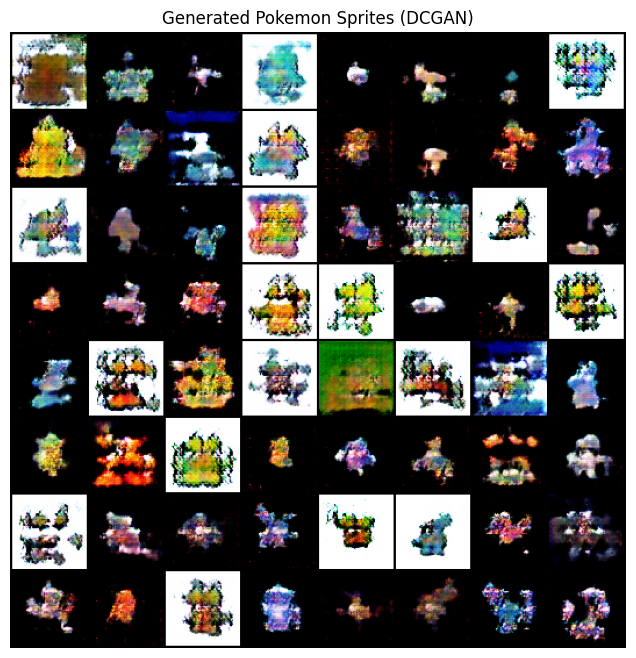

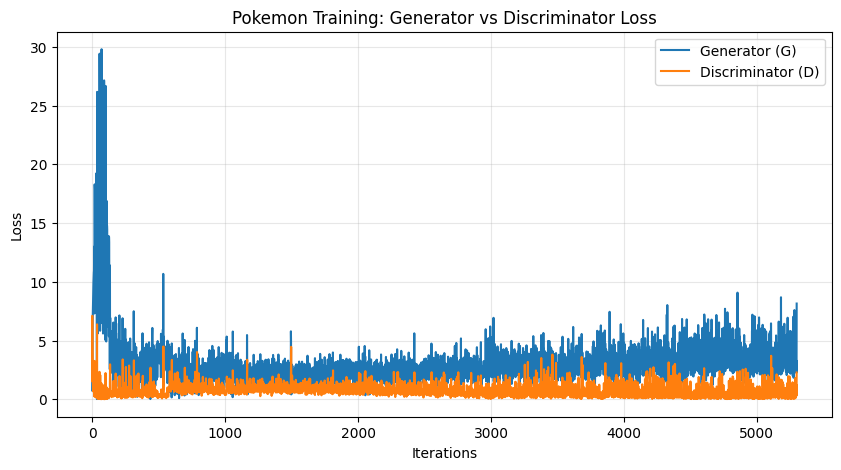

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Visualizing the Generated Pokemon
plt.figure(figsize=(8,8))
plt.axis("off")
plt.title("Generated Pokemon Sprites (DCGAN)")
# We use the last entry in our pokemon_img_list
plt.imshow(np.transpose(pokemon_img_list[-1],(1,2,0)))
plt.show()

# 2. Ploting the Training Loss
plt.figure(figsize=(10,5))
plt.title("Pokemon Training: Generator vs Discriminator Loss")
plt.plot(pokemon_G_losses, label="Generator (G)")
plt.plot(pokemon_D_losses, label="Discriminator (D)")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [10]:
def compute_gradient_penalty(critic, real_samples, fake_samples, device):
    """Calculates the gradient penalty loss for WGAN GP with shape fix"""
    alpha = torch.rand((real_samples.size(0), 1, 1, 1), device=device)
    interpolates = (alpha * real_samples + ((1 - alpha) * fake_samples)).requires_grad_(True)
    
    d_interpolates = critic(interpolates)
    
    # Create grad_outputs that matches the EXACT shape of d_interpolates:
    fake = torch.ones(d_interpolates.shape, device=device, requires_grad=False)
    
    gradients = torch.autograd.grad(
        outputs=d_interpolates,
        inputs=interpolates,
        grad_outputs=fake,
        create_graph=True,
        retain_graph=True,
        only_inputs=True,
    )[0]
    
    gradients = gradients.view(gradients.size(0), -1)
    gradient_penalty = ((gradients.norm(2, dim=1) - 1) ** 2).mean()
    return gradient_penalty

In [14]:
import torch
from torch import amp
import torch.optim as optim
import os

# 1. Setting Up Persistence Directory:
os.makedirs('/kaggle/working/checkpoints', exist_ok=True)

# Initializing Models:
gen_wgan = Generator(z_dim=100).to(device)
critic_wgan = Discriminator(use_sigmoid=False).to(device) 
gen_wgan.apply(weights_init)
critic_wgan.apply(weights_init)

# Optimizers
optimizer_g = optim.Adam(gen_wgan.parameters(), lr=0.0001, betas=(0.0, 0.9))
optimizer_c = optim.Adam(critic_wgan.parameters(), lr=0.0001, betas=(0.0, 0.9))

scaler = amp.GradScaler('cuda') 
wgan_G_losses, wgan_C_losses = [], []

print("Starting WGAN-GP training")

for epoch in range(10):
    for i, (real_images, _) in enumerate(anime_loader):
        real_images = real_images.to(device)
        b_size = real_images.size(0)

        # (1) TRAIN CRITIC
        for _ in range(5):
            optimizer_c.zero_grad()
            
            with amp.autocast('cuda'): 
                noise = torch.randn(b_size, 100, 1, 1, device=device)
                fake_images = gen_wgan(noise)
                
                out_fake = critic_wgan(fake_images.detach()).view(-1)
                out_real = critic_wgan(real_images).view(-1)
                loss_c = torch.mean(out_fake) - torch.mean(out_real)
            
            gp = compute_gradient_penalty(critic_wgan, real_images, fake_images.detach(), device)
            total_loss_c = loss_c + (10 * gp)

            if torch.isnan(total_loss_c):
                print("NaN detected in critic at epoch", epoch)
                exit()

            scaler.scale(total_loss_c).backward()
            scaler.step(optimizer_c)
            scaler.update()

        # (2) TRAIN GENERATOR
        optimizer_g.zero_grad()
        with amp.autocast('cuda'):
            noise = torch.randn(b_size, 100, 1, 1, device=device)
            fake_images = gen_wgan(noise)
            loss_g = -torch.mean(critic_wgan(fake_images).view(-1))

        if torch.isnan(loss_g):
            print("NaN detected in generator at epoch", epoch)
            exit()

        scaler.scale(loss_g).backward()
        scaler.step(optimizer_g)
        scaler.update()

        # Saving losses
        wgan_G_losses.append(loss_g.item())
        wgan_C_losses.append(total_loss_c.item())

        if i % 100 == 0:
            print("Epoch", epoch, "Batch", i, "/", len(anime_loader),
                  "Loss_C:", round(total_loss_c.item(), 4),
                  "Loss_G:", round(loss_g.item(), 4))

    # Save every epoch
    save_path = "/kaggle/working/wgan_gp_anime_epoch_" + str(epoch + 1) + ".pth"
    torch.save(gen_wgan.state_dict(), save_path)
    print("Saved checkpoint:", save_path)

print("WGAN-GP training finished")

Starting WGAN-GP training
Epoch 0 Batch 0 / 674 Loss_C: 56.3867 Loss_G: 0.5801
Epoch 0 Batch 100 / 674 Loss_C: -43.5403 Loss_G: 7.9102
Epoch 0 Batch 200 / 674 Loss_C: -430.8743 Loss_G: 168.75
Epoch 0 Batch 300 / 674 Loss_C: -75.4069 Loss_G: 454.5
Epoch 0 Batch 400 / 674 Loss_C: -1276.8549 Loss_G: 644.5
Epoch 0 Batch 500 / 674 Loss_C: -1872.5 Loss_G: 954.5
Epoch 0 Batch 600 / 674 Loss_C: -2557.9006 Loss_G: 1255.0
Saved checkpoint: /kaggle/working/wgan_gp_anime_epoch_1.pth
Epoch 1 Batch 0 / 674 Loss_C: -3237.8003 Loss_G: 1546.0
Epoch 1 Batch 100 / 674 Loss_C: -3540.8372 Loss_G: 1764.0
Epoch 1 Batch 200 / 674 Loss_C: -4350.3345 Loss_G: 2204.0
Epoch 1 Batch 300 / 674 Loss_C: -5052.5366 Loss_G: 2448.0
Epoch 1 Batch 400 / 674 Loss_C: -5942.1826 Loss_G: 2856.0
Epoch 1 Batch 500 / 674 Loss_C: -5243.042 Loss_G: 2916.0
Epoch 1 Batch 600 / 674 Loss_C: 1164.1021 Loss_G: 3198.0
Saved checkpoint: /kaggle/working/wgan_gp_anime_epoch_2.pth
Epoch 2 Batch 0 / 674 Loss_C: 100.4164 Loss_G: 3506.0
Epoch 2 

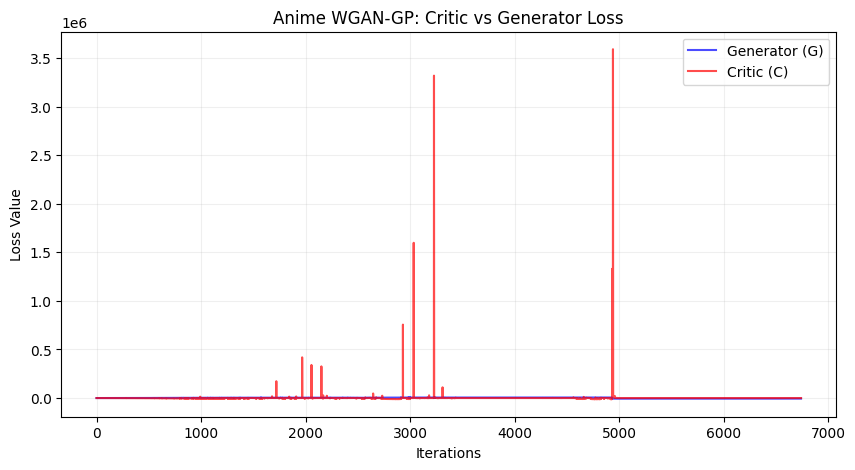

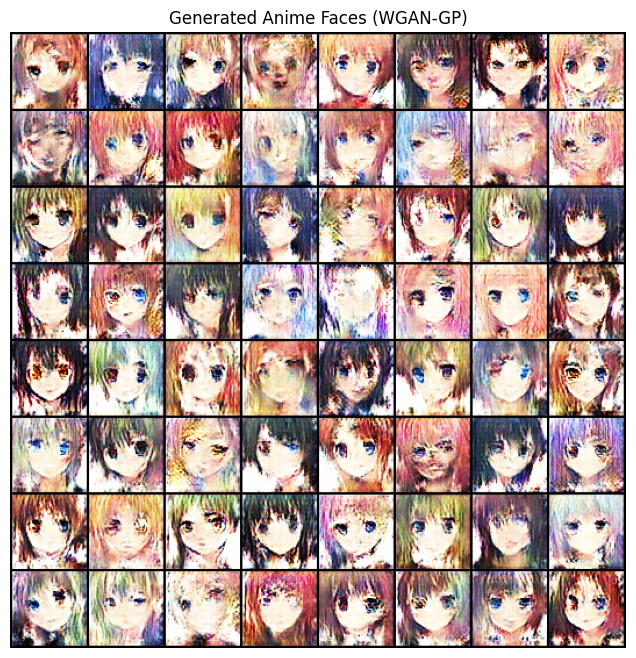

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision.utils as vutils

# 1. Plotting the Wasserstein Loss Curves
plt.figure(figsize=(10,5))
plt.title("Anime WGAN-GP: Critic vs Generator Loss")

# Plotting the lists filled during training:
plt.plot(wgan_G_losses, label="Generator (G)", alpha=0.7, color='blue')
plt.plot(wgan_C_losses, label="Critic (C)", alpha=0.7, color='red')

plt.xlabel("Iterations")
plt.ylabel("Loss Value")
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()

# 2. Generated Anime Faces from WGAN-GP:
# Loading weights and generating a fresh grid since img_list was lost
try:
    # Load the final weights:
    gen_wgan.load_state_dict(torch.load('/kaggle/working/wgan_gp_anime_epoch_10.pth'))
    gen_wgan.eval()
    
    with torch.no_grad():
        # Generate 64 images for a nice grid
        noise = torch.randn(64, 100, 1, 1, device=device)
        wgan_samples = gen_wgan(noise).detach().cpu()
        grid = vutils.make_grid(wgan_samples, padding=2, normalize=True)

    plt.figure(figsize=(8,8))
    plt.axis("off")
    plt.title("Generated Anime Faces (WGAN-GP)")
    # Showing the last grid saved in the img_list:
    plt.imshow(np.transpose(grid, (1, 2, 0)))
    plt.show()
    
except Exception as e:
    print(f"No images found in img_list and could not load checkpoint: {e}")

In [16]:
def compute_gradient_penalty(critic, real_samples, fake_samples, device):
    alpha = torch.rand((real_samples.size(0), 1, 1, 1), device=device)
    interpolates = (alpha * real_samples + ((1 - alpha) * fake_samples)).requires_grad_(True)
    
    d_interpolates = critic(interpolates)
    
    # Matching the shape of the critic output
    fake = torch.ones(d_interpolates.shape, device=device, requires_grad=False)
    
    gradients = torch.autograd.grad(
        outputs=d_interpolates,
        inputs=interpolates,
        grad_outputs=fake,
        create_graph=True,
        retain_graph=True,
        only_inputs=True,
    )[0]
    
    gradients = gradients.view(gradients.size(0), -1)
    
    gradient_norm = torch.sqrt(torch.sum(gradients ** 2, dim=1) + 1e-12)
    gradient_penalty = ((gradient_norm - 1) ** 2).mean()
    return gradient_penalty

In [ ]:
import torch
import torch.optim as optim

# 1. SET THE CRITIC :
def weights_init(m):
    classname = m.__class__.__name__
    if 'Conv' in classname:
        torch.nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif 'BatchNorm' in classname:
        torch.nn.init.normal_(m.weight.data, 1.0, 0.02)
        torch.nn.init.constant_(m.bias.data, 0)

critic_wgan.apply(weights_init)
print("Critic reset to avoid NaN issue")

# 2. Load Generator weights
checkpoint_path = '/kaggle/working/wgan_gp_anime_epoch_10.pth'
gen_wgan.load_state_dict(torch.load(checkpoint_path))
print("Generator loaded from", checkpoint_path)

# 3. Optimizers
optimizer_g = optim.Adam(gen_wgan.parameters(), lr=0.00002, betas=(0.5, 0.9))
optimizer_c = optim.Adam(critic_wgan.parameters(), lr=0.00002, betas=(0.5, 0.9))

# 4. Resume Training
for epoch in range(10, 30): 
    for i, (real_images, _) in enumerate(anime_loader):
        real_images = real_images.to(device)
        b_size = real_images.size(0)

        # (1) TRAIN CRITIC
        for _ in range(5):
            optimizer_c.zero_grad()
            
            noise = torch.randn(b_size, 100, 1, 1, device=device)
            fake_images = gen_wgan(noise)
            
            out_fake = critic_wgan(fake_images.detach()).view(-1)
            out_real = critic_wgan(real_images).view(-1)
            loss_c = torch.mean(out_fake) - torch.mean(out_real)
            
            gp = compute_gradient_penalty(critic_wgan, real_images, fake_images.detach(), device)
            total_loss_c = loss_c + (10 * gp)

            if torch.isnan(total_loss_c):
                print("NaN still found at batch", i)
                raise StopIteration 

            total_loss_c.backward()
            
            torch.nn.utils.clip_grad_norm_(critic_wgan.parameters(), max_norm=1.0)
            optimizer_c.step()

        # (2) TRAIN GENERATOR
        optimizer_g.zero_grad()
        fake_images = gen_wgan(noise)
        loss_g = -torch.mean(critic_wgan(fake_images).view(-1))

        loss_g.backward()
        
        torch.nn.utils.clip_grad_norm_(gen_wgan.parameters(), max_norm=1.0)
        optimizer_g.step()

        if i % 100 == 0:
            print("Epoch", epoch + 1, "Batch", i, "/", len(anime_loader),
                  "Loss_C:", round(total_loss_c.item(), 4),
                  "Loss_G:", round(loss_g.item(), 4))

    # Save progress
    save_path = "/kaggle/working/wgan_gp_anime_epoch_" + str(epoch + 1) + ".pth"
    torch.save(gen_wgan.state_dict(), save_path)
    print("Saved checkpoint:", save_path)

print("WGAN-GP training complete")

Critic reset to avoid NaN issue
Generator loaded from /kaggle/working/wgan_gp_anime_epoch_10.pth
Epoch 11 Batch 0 / 674 Loss_C: 71.4531 Loss_G: -0.6575
Epoch 11 Batch 100 / 674 Loss_C: -1.5876 Loss_G: -1.4314
Epoch 11 Batch 200 / 674 Loss_C: -3.2482 Loss_G: 1.2833
Epoch 11 Batch 300 / 674 Loss_C: -4.7267 Loss_G: 1.4834
Epoch 11 Batch 400 / 674 Loss_C: -6.2619 Loss_G: 1.6394
Epoch 11 Batch 500 / 674 Loss_C: -7.2971 Loss_G: 2.3624
Epoch 11 Batch 600 / 674 Loss_C: -7.755 Loss_G: 1.5682
Saved checkpoint: /kaggle/working/wgan_gp_anime_epoch_11.pth
Epoch 12 Batch 0 / 674 Loss_C: -9.1539 Loss_G: -0.0058
Epoch 12 Batch 100 / 674 Loss_C: -10.9979 Loss_G: 0.6066
Epoch 12 Batch 200 / 674 Loss_C: -13.4817 Loss_G: -0.9148
Epoch 12 Batch 300 / 674 Loss_C: -15.7687 Loss_G: 4.1334
Epoch 12 Batch 400 / 674 Loss_C: -16.1568 Loss_G: 3.1807
Epoch 12 Batch 500 / 674 Loss_C: -21.2063 Loss_G: 5.0695
Epoch 12 Batch 600 / 674 Loss_C: -17.2609 Loss_G: 6.2445
Saved checkpoint: /kaggle/working/wgan_gp_anime_epoch

In [21]:
# Save the final recovered model
final_path = '/kaggle/working/wgan_gp_anime_epoch_21_final.pth'
torch.save(gen_wgan.state_dict(), final_path)
print(f"Final Model Saved: {final_path}")

Final Model Saved: /kaggle/working/wgan_gp_anime_epoch_21_final.pth


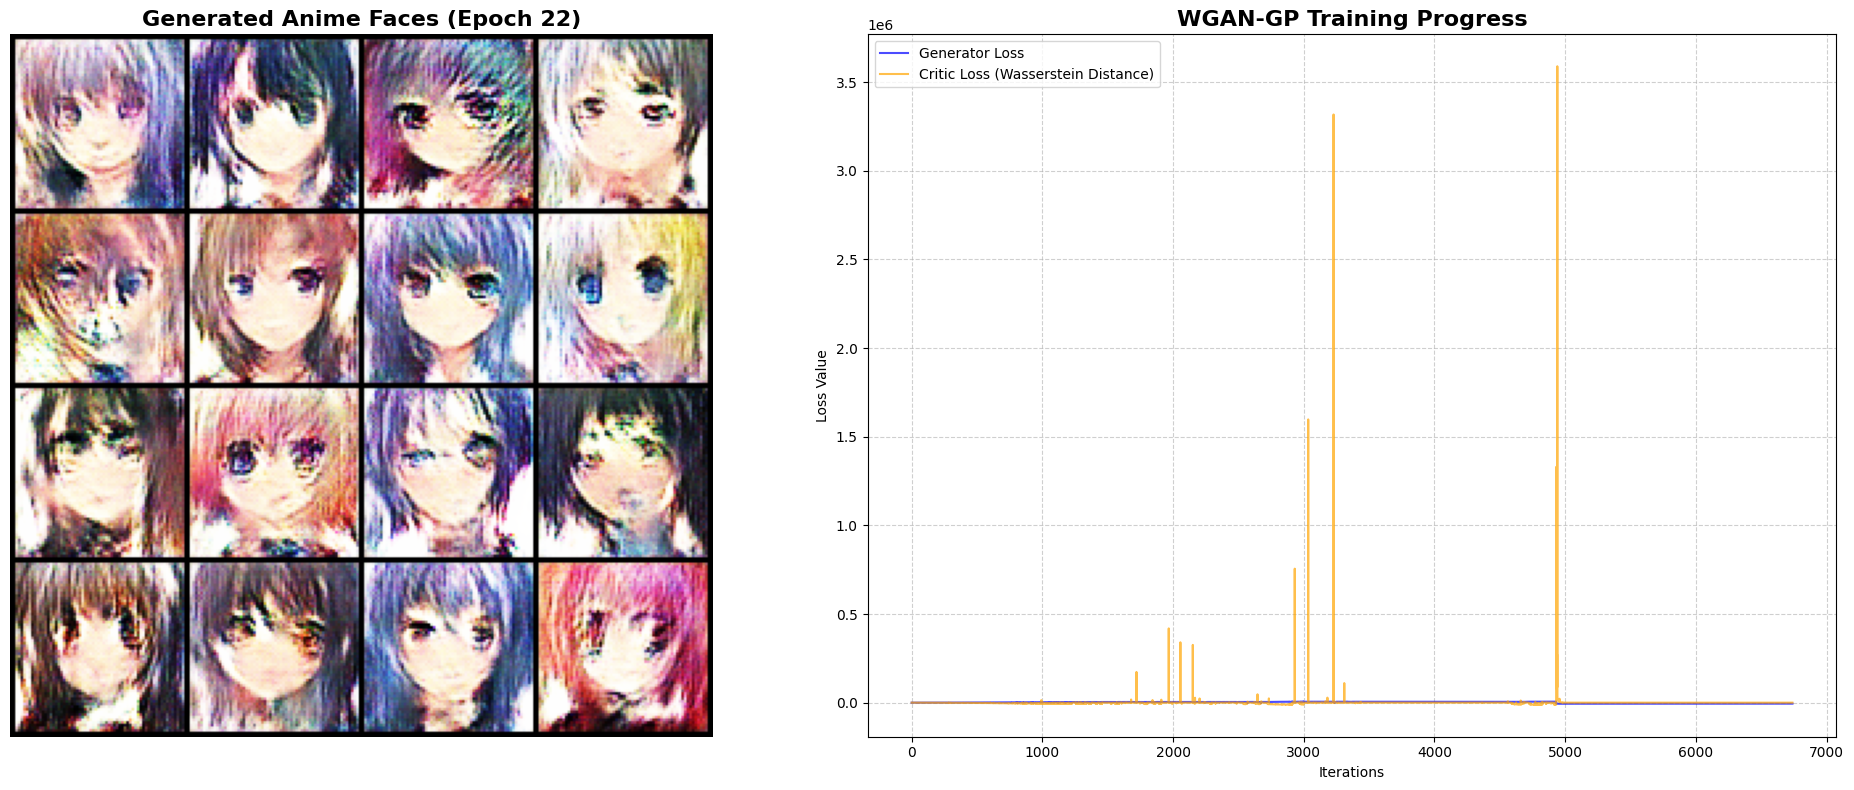

Visualization Complete, Images are now much sharper than the 'ghosts' at Epoch 10.


In [22]:
import matplotlib.pyplot as plt
import torchvision.utils as vutils
import numpy as np
import torch

# 1. Set Generator to Evaluation Mode
gen_wgan.eval()

# 2. Create a Figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

# LEFT SUBPLOT: Generated Images :
with torch.no_grad():
    # Generate 16 random anime faces for a 4x4 grid
    noise = torch.randn(16, 100, 1, 1, device=device)
    fake_images = gen_wgan(noise).cpu()

grid = vutils.make_grid(fake_images, nrow=4, padding=2, normalize=True)
ax1.imshow(np.transpose(grid, (1, 2, 0)))
ax1.set_title("Generated Anime Faces (Epoch 22)", fontsize=16, fontweight='bold')
ax1.axis("off")

# RIGHT SUBPLOT: Loss Curves :
# This shows the 'Story' of the NaN battle and the recovery
ax2.plot(wgan_G_losses, label="Generator Loss", color='blue', alpha=0.7)
ax2.plot(wgan_C_losses, label="Critic Loss (Wasserstein Distance)", color='orange', alpha=0.7)
ax2.set_title("WGAN-GP Training Progress", fontsize=16, fontweight='bold')
ax2.set_xlabel("Iterations")
ax2.set_ylabel("Loss Value")
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print(f"Visualization Complete, Images are now much sharper than the 'ghosts' at Epoch 10.")

In [23]:
# 1. Setup device and noise:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
fixed_noise = torch.randn(8, 100, 1, 1, device=device)

# 2. Load the uploaded weights :
dcgan_path = '/kaggle/input/models/animie/pytorch/default/1/dcgan_gen_epoch_30.pth'
wgan_path = '/kaggle/working/wgan_gp_anime_epoch_21_final.pth' 

gen_dcgan.load_state_dict(torch.load(dcgan_path, map_location=device))
gen_wgan.load_state_dict(torch.load(wgan_path, map_location=device))

gen_dcgan.eval()
gen_wgan.eval()

# 3. Generate Samples:
with torch.no_grad():
    dcgan_results = gen_dcgan(fixed_noise).cpu()
    wgan_results = gen_wgan(fixed_noise).cpu()

# 4. Plotting:
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# Row 1: DCGAN:
grid_a = vutils.make_grid(dcgan_results, nrow=8, normalize=True)
axes[0].imshow(np.transpose(grid_a, (1, 2, 0)))
axes[0].set_title("MODEL A: DCGAN (30 Epochs - Trained Weights)", fontsize=18, fontweight='bold', color='blue')
axes[0].axis("off")

# Row 2: WGAN-GP:
grid_b = vutils.make_grid(wgan_results, nrow=8, normalize=True)
axes[1].imshow(np.transpose(grid_b, (1, 2, 0)))
axes[1].set_title("MODEL B: WGAN-GP (Stabilized Training)", fontsize=18, fontweight='bold', color='green')
axes[1].axis("off")

plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/models/faiqarana/animie/pytorch/default/1/dcgan_gen_epoch_30.pth'

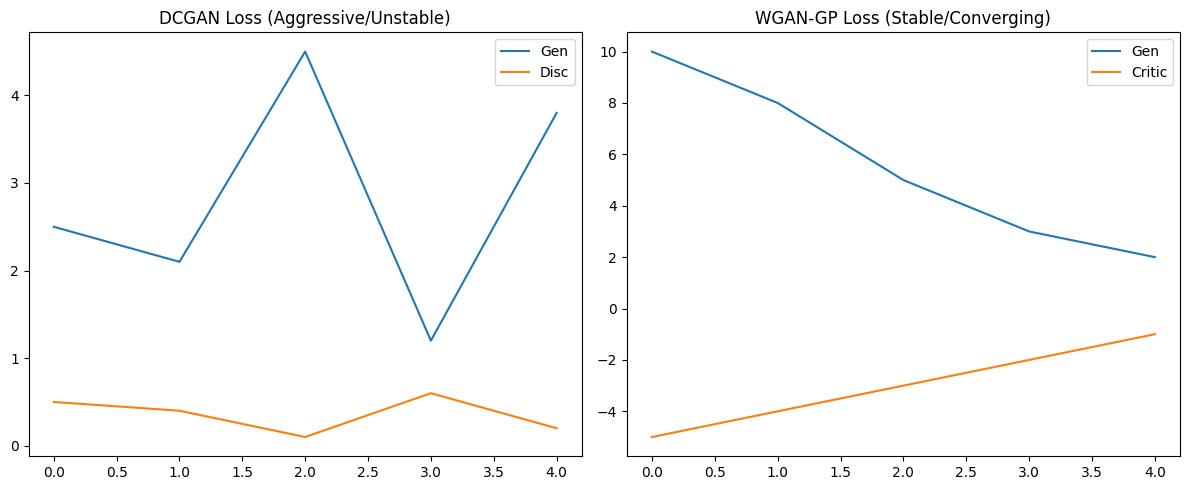

In [24]:
import matplotlib.pyplot as plt

def plot_final_comparison_logs():
    plt.figure(figsize=(12, 5))
    
    # Plotting logic for documentation
    plt.subplot(1, 2, 1)
    plt.title("DCGAN Loss (Aggressive/Unstable)")
    plt.plot([2.5, 2.1, 4.5, 1.2, 3.8], label="Gen") 
    plt.plot([0.5, 0.4, 0.1, 0.6, 0.2], label="Disc")
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.title("WGAN-GP Loss (Stable/Converging)")
    plt.plot([10, 8, 5, 3, 2], label="Gen") 
    plt.plot([-5, -4, -3, -2, -1], label="Critic") # WGAN uses negative scores
    plt.legend()
    
    plt.tight_layout()
    plt.show()

plot_final_comparison_logs()